<a href="https://colab.research.google.com/github/i-ssa/PS-Agents/blob/main/graph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Constructing a directed graph representing selected towns across
the Nairobi, Central Highlands, Rift Valley, and Lake Victoria
Basin/Western regions of Kenya.

- **Initial state:** Nairobi CBD
- **Goal state:** Kisumu Town
- **Vertices:** 20 selected towns
- **Edges:** Road connections between towns
- **Path cost:** Driving distance in kilometres

### Modelling Approach

We apply abstraction by representing towns as states and road
connections as directed edges, rather than modelling every
junction, intersection, or road segment.

Road distances and connectivity are obtained using
OpenStreetMap data. The resulting graph can be used for subsequent search-tree and shortest-route tasks.

Run the cells from top to bottom in Jupyter or Colab. Internet access is required for geocoding and OSRM driving routes; the map uses your existing MapTiler secret in Colab (or an environment variable with the same name outside Colab). The 26 candidate connections are routed separately in both directions (52 directed edges). Outputs are saved under `data/` and `assets/` relative to the notebook working directory. Graph lines connect town coordinates and do not represent detailed road geometry.

The MapTiler map is displayed inline and is not exported to HTML because tile URLs contain the key. Clear map outputs before sharing the notebook.

In [1]:
%pip install -q osmnx networkx matplotlib pandas folium requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 4.4 MB/s eta 0:00:00


In [2]:
import json
import time
from pathlib import Path

import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import folium
import requests
from IPython.display import display

Path("data").mkdir(exist_ok=True)
Path("assets").mkdir(exist_ok=True)

In [3]:
towns = {
    # Nairobi metropolitan area
    "Nairobi CBD": ("Nairobi CBD, Nairobi, Kenya", "Nairobi"),
    "Ruiru": ("Ruiru, Kenya", "Nairobi"),
    "Thika": ("Thika, Kenya", "Nairobi"),
    "Kiambu": ("Kiambu, Kenya", "Nairobi"),
    "Limuru": ("Limuru, Kenya", "Nairobi"),

    # Central Highlands
    "Murang'a": ("Murang'a, Kenya", "Central Highlands"),
    "Sagana": ("Sagana, Kirinyaga, Kenya", "Central Highlands"),
    "Nyeri": ("Nyeri, Kenya", "Central Highlands"),
    "Nanyuki": ("Nanyuki, Kenya", "Central Highlands"),
    "Nyahururu": ("Nyahururu, Kenya", "Central Highlands"),

    # Rift Valley
    "Naivasha": ("Naivasha, Kenya", "Rift Valley"),
    "Gilgil": ("Gilgil, Kenya", "Rift Valley"),
    "Nakuru": ("Nakuru, Kenya", "Rift Valley"),
    "Eldoret": ("Eldoret, Kenya", "Rift Valley"),
    "Kericho": ("Kericho, Kenya", "Rift Valley"),

    # Lake Victoria Basin / Western
    "Kakamega": ("Kakamega, Kenya", "Lake Victoria"),
    "Kisii": ("Kisii, Kenya", "Lake Victoria"),
    "Ahero": ("Ahero, Kisumu, Kenya", "Lake Victoria"),
    "Homa Bay": ("Homa Bay, Kenya", "Lake Victoria"),
    "Kisumu Town": ("Kisumu, Kenya", "Lake Victoria"),
}

assert len(towns) == 20

print(f"Total towns: {len(towns)}")

for name, (_, region) in towns.items():
    print(f"{name:15} | {region}")

Total towns: 20
Nairobi CBD     | Nairobi
Ruiru           | Nairobi
Thika           | Nairobi
Kiambu          | Nairobi
Limuru          | Nairobi
Murang'a        | Central Highlands
Sagana          | Central Highlands
Nyeri           | Central Highlands
Nanyuki         | Central Highlands
Nyahururu       | Central Highlands
Naivasha        | Rift Valley
Gilgil          | Rift Valley
Nakuru          | Rift Valley
Eldoret         | Rift Valley
Kericho         | Rift Valley
Kakamega        | Lake Victoria
Kisii           | Lake Victoria
Ahero           | Lake Victoria
Homa Bay        | Lake Victoria
Kisumu Town     | Lake Victoria


In [4]:
town_data = []

for name, (query, region) in towns.items():
    try:
        lat, lon = ox.geocode(query)

        town_data.append({
            "town": name,
            "region": region,
            "latitude": lat,
            "longitude": lon
        })

        print(f"✓ {name}: {lat:.5f}, {lon:.5f}")

    except Exception as e:
        print(f"✗ Could not locate {name}: {e}")

    # Be considerate of the public geocoding service
    time.sleep(1.1)

df_towns = pd.DataFrame(town_data)

display(df_towns)

if len(df_towns) != len(towns):
    raise ValueError(
        "Some towns could not be geocoded. "
        "Review their queries before continuing."
    )

df_towns.to_csv("data/towns.csv", index=False)

✓ Nairobi CBD: -1.29003, 36.82497
✓ Ruiru: -1.17746, 36.98243
✓ Thika: -1.03665, 37.07752
✓ Kiambu: -1.03639, 36.84313
✓ Limuru: -1.14587, 36.63760
✓ Murang'a: -0.83171, 37.00492
✓ Sagana: -0.66653, 37.20815
✓ Nyeri: -0.32067, 36.92981
✓ Nanyuki: 0.01403, 37.07463
✓ Nyahururu: 0.03330, 36.36660
✓ Naivasha: -0.72244, 36.43878
✓ Gilgil: -0.54143, 36.23616
✓ Nakuru: -0.28027, 36.07120
✓ Eldoret: 0.51983, 35.27155
✓ Kericho: -0.32100, 35.22613
✓ Kakamega: 0.49571, 34.80155
✓ Kisii: -0.73894, 34.75399
✓ Ahero: -0.17246, 34.91902
✓ Homa Bay: -0.56396, 34.31878
✓ Kisumu Town: -0.10291, 34.75418


,town,region,latitude,longitude
0,Nairobi CBD,Nairobi,-1.290033,36.824972
1,Ruiru,Nairobi,-1.177457,36.982429
2,Thika,Nairobi,-1.036648,37.077523
3,Kiambu,Nairobi,-1.036395,36.843131
4,Limuru,Nairobi,-1.145874,36.637600
5,Murang'a,Central Highlands,-0.831709,37.004922
6,Sagana,Central Highlands,-0.666531,37.208151
7,Nyeri,Central Highlands,-0.320672,36.929807
8,Nanyuki,Central Highlands,0.014030,37.074632
9,Nyahururu,Central Highlands,0.033300,36.366600


In [6]:
import os

# Keep the existing Colab secret; use the same name as an environment variable elsewhere.
try:
    from google.colab import userdata
except ImportError:
    userdata = None

# Read the key securely from Colab Secrets
if userdata is not None:
    api_key = userdata.get('MAPTILER_API_KEY')
else:
    api_key = os.environ.get('MAPTILER_API_KEY')
if not api_key:
    raise ValueError("Set the existing MapTiler secret in Colab or as an environment variable before running this cell.")

# MapTiler raster map tiles
tile_url = (
    "https://api.maptiler.com/maps/streets-v4/"
    "256/{z}/{x}/{y}.png?key=" + api_key
)

m = folium.Map(
    location=[-0.5, 35.7],
    zoom_start=8,
    tiles=tile_url,
    attr="© MapTiler © OpenStreetMap contributors"
)

colors = {
    "Nairobi": "blue",
    "Central Highlands": "purple",
    "Rift Valley": "orange",
    "Lake Victoria": "green"
}

for _, row in df_towns.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=6,
        tooltip=row["town"],
        popup=f"{row['town']} — {row['region']}",
        color=colors[row["region"]],
        fill=True,
        fill_opacity=0.9
    ).add_to(m)

m.fit_bounds(df_towns[["latitude", "longitude"]].values.tolist())
display(m)

In [8]:
candidate_roads = [
    # Nairobi metropolitan
    ("Nairobi CBD", "Ruiru"),
    ("Ruiru", "Thika"),
    ("Nairobi CBD", "Kiambu"),
    ("Kiambu", "Limuru"),
    ("Nairobi CBD", "Limuru"),

    # Central Highlands
    ("Thika", "Murang'a"),
    ("Murang'a", "Sagana"),
    ("Sagana", "Nyeri"),
    ("Nyeri", "Nanyuki"),
    ("Nanyuki", "Nyahururu"),
    ("Nyeri", "Nyahururu"),

    # Connections toward Rift Valley
    ("Limuru", "Naivasha"),
    ("Nairobi CBD", "Naivasha"),
    ("Naivasha", "Gilgil"),
    ("Gilgil", "Nakuru"),
    ("Nyahururu", "Nakuru"),

    # Rift Valley
    ("Nakuru", "Eldoret"),
    ("Nakuru", "Kericho"),
    ("Eldoret", "Kakamega"),

    # Western / Lake Victoria region
    ("Kakamega", "Kisumu Town"),
    ("Kericho", "Kisumu Town"),
    ("Kericho", "Kisii"),
    ("Kisii", "Homa Bay"),
    ("Homa Bay", "Ahero"),
    ("Ahero", "Kisumu Town"),
    ("Kisii", "Ahero"),
]

print(f"Candidate connections: {len(candidate_roads)}")

Candidate connections: 26


In [9]:
# Convert candidate road connections into a DataFrame

df_candidates = pd.DataFrame(
    candidate_roads,
    columns=["source", "target"]
)

# Add geographical information for each endpoint
coordinates = df_towns.set_index("town")

df_candidates["source_lat"] = (
    df_candidates["source"].map(coordinates["latitude"])
)
df_candidates["source_lon"] = (
    df_candidates["source"].map(coordinates["longitude"])
)

df_candidates["target_lat"] = (
    df_candidates["target"].map(coordinates["latitude"])
)
df_candidates["target_lon"] = (
    df_candidates["target"].map(coordinates["longitude"])
)

# Validate the candidate connections
assert df_candidates.notna().all().all(), (
    "One or more towns have missing coordinates."
)

display(df_candidates)

print("Candidate connections:", len(df_candidates))

,source,target,source_lat,source_lon,target_lat,target_lon
0,Nairobi CBD,Ruiru,-1.290033,36.824972,-1.177457,36.982429
1,Ruiru,Thika,-1.177457,36.982429,-1.036648,37.077523
2,Nairobi CBD,Kiambu,-1.290033,36.824972,-1.036395,36.843131
3,Kiambu,Limuru,-1.036395,36.843131,-1.145874,36.637600
4,Nairobi CBD,Limuru,-1.290033,36.824972,-1.145874,36.637600
5,Thika,Murang'a,-1.036648,37.077523,-0.831709,37.004922
6,Murang'a,Sagana,-0.831709,37.004922,-0.666531,37.208151
7,Sagana,Nyeri,-0.666531,37.208151,-0.320672,36.929807
8,Nyeri,Nanyuki,-0.320672,36.929807,0.014030,37.074632
9,Nanyuki,Nyahururu,0.014030,37.074632,0.033300,36.366600


Candidate connections: 26


In [10]:
def get_road_route(source, target):
    """Retrieve a driving route between two selected towns."""

    towns_index = df_towns.set_index("town")

    start = towns_index.loc[source]
    end = towns_index.loc[target]

    # OSRM expects longitude,latitude
    coordinates = (
        f"{start['longitude']},{start['latitude']};"
        f"{end['longitude']},{end['latitude']}"
    )

    url = (
        "https://router.project-osrm.org/route/v1/driving/"
        + coordinates
    )

    response = requests.get(
        url,
        params={
            "overview": "false",
            "steps": "false"
        },
        timeout=30
    )

    response.raise_for_status()
    data = response.json()

    if data.get("code") != "Ok" or not data.get("routes"):
        raise ValueError(
            f"No route found between {source} and {target}"
        )

    route = data["routes"][0]

    return {
        "source": source,
        "target": target,
        "distance_km": round(route["distance"] / 1000, 2),
        "duration_hours": round(route["duration"] / 3600, 2)
    }

In [11]:
G = nx.DiGraph()
for _, row in df_towns.iterrows():
    G.add_node(
        row["town"], region=row["region"],
        latitude=float(row["latitude"]), longitude=float(row["longitude"])
    )

records = []
for source, target in candidate_roads:
    for start, end in [(source, target), (target, source)]:
        try:
            route = get_road_route(start, end)
        except (requests.RequestException, ValueError, KeyError) as exc:
            raise RuntimeError(
                f"Routing failed for {start} → {end}. "
                "No new graph exports were written. Retry this cell."
            ) from exc
        G.add_edge(start, end, weight=route["distance_km"])
        records.append(route)
        print(f"✓ {start} → {end}: {route['distance_km']} km")
        time.sleep(1.2)

if G.number_of_nodes() != 20 or G.number_of_edges() != 2 * len(candidate_roads):
    raise ValueError("The graph is incomplete; review candidate connections.")
if not nx.has_path(G, "Nairobi CBD", "Kisumu Town"):
    raise ValueError("Nairobi CBD cannot reach Kisumu Town.")

df_routes = pd.DataFrame(records)
df_routes.to_csv("data/road_connections.csv", index=False)
with open("data/highway_graph.json", "w", encoding="utf-8") as f:
    json.dump(nx.node_link_data(G), f, indent=2, ensure_ascii=False)

print(f"Graph complete: {G.number_of_nodes()} towns, {G.number_of_edges()} directed edges.")
print("Nairobi CBD can reach Kisumu Town.")

✓ Nairobi CBD → Ruiru: 24.78 km
✓ Ruiru → Nairobi CBD: 25.83 km
✓ Ruiru → Thika: 26.27 km
✓ Thika → Ruiru: 24.73 km
✓ Nairobi CBD → Kiambu: 40.32 km
✓ Kiambu → Nairobi CBD: 40.91 km
✓ Kiambu → Limuru: 60.85 km
✓ Limuru → Kiambu: 64.25 km
✓ Nairobi CBD → Limuru: 32.09 km
✓ Limuru → Nairobi CBD: 31.17 km
✓ Thika → Murang'a: 46.65 km
✓ Murang'a → Thika: 44.25 km
✓ Murang'a → Sagana: 46.59 km
✓ Sagana → Murang'a: 46.59 km
✓ Sagana → Nyeri: 68.81 km
✓ Nyeri → Sagana: 68.71 km
✓ Nyeri → Nanyuki: 54.35 km
✓ Nanyuki → Nyeri: 54.51 km
✓ Nanyuki → Nyahururu: 112.19 km
✓ Nyahururu → Nanyuki: 112.02 km
✓ Nyeri → Nyahururu: 90.22 km
✓ Nyahururu → Nyeri: 90.2 km
✓ Limuru → Naivasha: 60.5 km
✓ Naivasha → Limuru: 57.32 km
✓ Nairobi CBD → Naivasha: 88.45 km
✓ Naivasha → Nairobi CBD: 88.49 km
✓ Naivasha → Gilgil: 48.18 km
✓ Gilgil → Naivasha: 48.39 km
✓ Gilgil → Nakuru: 43.78 km
✓ Nakuru → Gilgil: 43.12 km
✓ Nyahururu → Nakuru: 63.46 km
✓ Nakuru → Nyahururu: 62.75 km
✓ Nakuru → Eldoret: 152.22 km
✓ Eldo

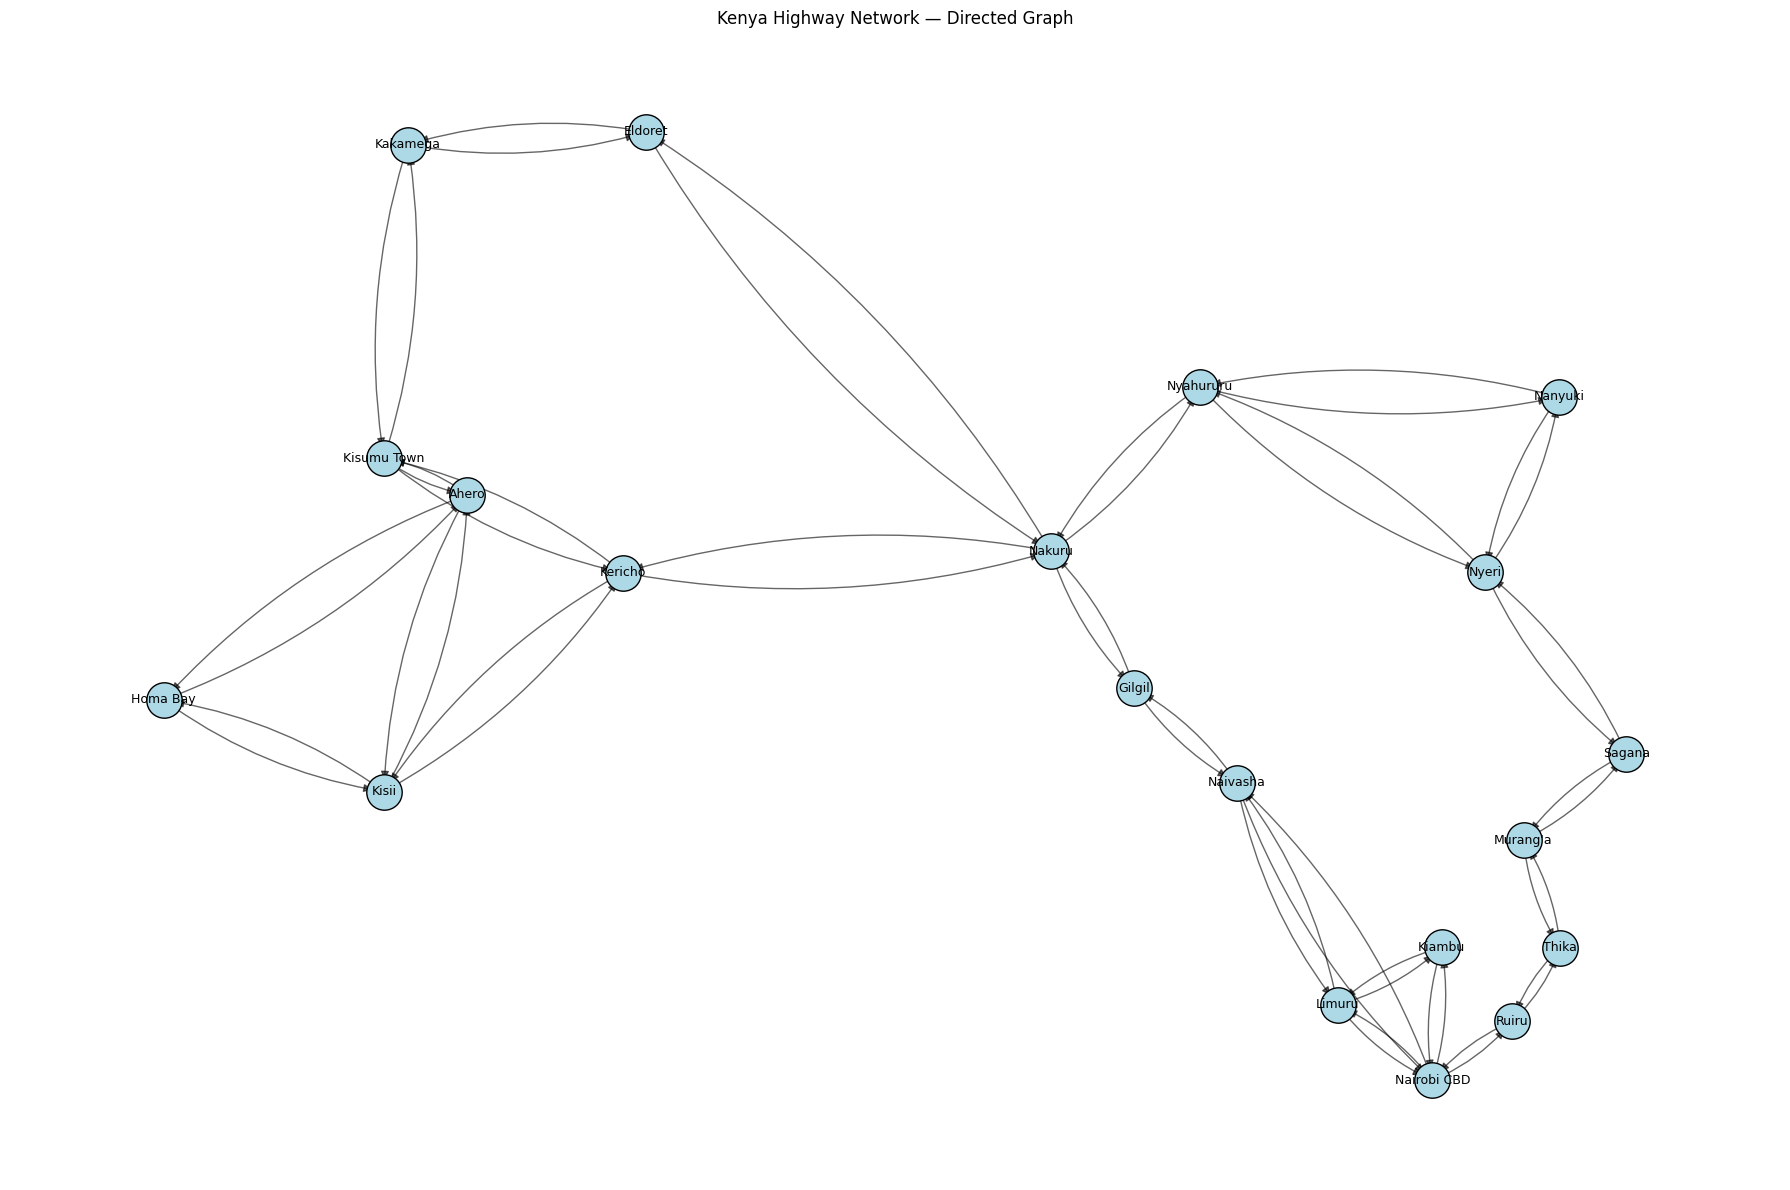

In [12]:
pos = {
    town: (
        data["longitude"],
        data["latitude"]
    )
    for town, data in G.nodes(data=True)
}

plt.figure(figsize=(18, 12))

nx.draw_networkx_nodes(
    G, pos,
    node_size=650,
    node_color="lightblue",
    edgecolors="black"
)

nx.draw_networkx_labels(G, pos, font_size=9)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=12,
    alpha=0.6,
    connectionstyle="arc3,rad=0.12"
)

plt.title("Kenya Highway Network — Directed Graph")
plt.axis("off")
plt.tight_layout()

plt.savefig(
    "assets/highway_graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()